# Shade correction prototype

**Question this answers:** with no historical data and no model of the kiln, can a tool
that learns from 8 planned test tiles fix a shade in fewer rounds than manual guessing?
And does it say so honestly when it *can't* fix something?

**How it is built (and why it is fair):**
- A **tile simulator** plays the role of the real printer + glaze + kiln. It is a
  non-linear, spectral model: ink absorption bands, dot gain, ink-load effects, a kiln
  that shifts both strength and hue, and glaze colour drift. The tool **never sees inside it**;
  it only gets noisy Lab readings, like a real spectrophotometer.
- The **tool** uses a much simpler model (straight-line sensitivities learned from 8 test
  tiles). Because the two models are different, the tool can't win "by design".
- The **manual baseline** is a *competent* operator: knows which way each ink moves the
  colour, picks the best ink each round, prints 6 variants, keeps the best.
- All random seeds are fixed at the top. Nothing was tuned after looking at the results.

Synthetic data proves the logic, not their kiln. The pilot is the real proof.

In [1]:
import numpy as np
from scipy.optimize import lsq_linear
import matplotlib.pyplot as plt

SEED = 2026
N_PRODUCTS = 200
TOL = 1.0            # pass/fail: mean ΔE00 over the measured spots
STEP = 0.15          # learning round: +15% on one ink per test tile
G_MIN, G_MAX = 0.70, 1.30   # allowed total ink gain vs the master file
NOISE = 0.12         # spectrophotometer noise per L, a, b reading
INKS = ["blue", "brown", "beige", "yellow", "pink", "black"]

## 1. Colour maths (Lab and ΔE00)
Spectrum → XYZ uses an analytic fit of the CIE 1931 observer (Wyman, Sloan & Shirley 2013),
equal-energy light, 400–700 nm in 10 nm steps. ΔE00 is the standard CIEDE2000 formula,
checked against a published test pair.

In [2]:
WL = np.arange(400, 701, 10.0)

def _lobe(x, mu, s1, s2):
    s = np.where(x < mu, s1, s2)
    return np.exp(-0.5 * ((x - mu) / s) ** 2)

XBAR = 1.056*_lobe(WL, 599.8, 37.9, 31.0) + 0.362*_lobe(WL, 442.0, 16.0, 26.7) - 0.065*_lobe(WL, 501.1, 20.4, 26.2)
YBAR = 0.821*_lobe(WL, 568.8, 46.9, 40.5) + 0.286*_lobe(WL, 530.9, 16.3, 31.1)
ZBAR = 1.217*_lobe(WL, 437.0, 11.8, 36.0) + 0.681*_lobe(WL, 459.0, 26.0, 13.8)
WHITE = np.array([XBAR.sum(), YBAR.sum(), ZBAR.sum()])

def spectrum_to_lab(R):
    xyz = np.stack([R @ XBAR, R @ YBAR, R @ ZBAR], -1) / WHITE
    f = np.where(xyz > (6/29)**3, np.cbrt(np.maximum(xyz, 0)), xyz / (3*(6/29)**2) + 4/29)
    return np.stack([116*f[..., 1] - 16, 500*(f[..., 0] - f[..., 1]), 200*(f[..., 1] - f[..., 2])], -1)

def de2000(lab1, lab2):
    L1, a1, b1 = np.moveaxis(np.asarray(lab1, float), -1, 0)
    L2, a2, b2 = np.moveaxis(np.asarray(lab2, float), -1, 0)
    Cm = (np.hypot(a1, b1) + np.hypot(a2, b2)) / 2
    G = 0.5 * (1 - np.sqrt(Cm**7 / (Cm**7 + 25**7)))
    a1p, a2p = (1 + G) * a1, (1 + G) * a2
    C1p, C2p = np.hypot(a1p, b1), np.hypot(a2p, b2)
    h1p = np.degrees(np.arctan2(b1, a1p)) % 360
    h2p = np.degrees(np.arctan2(b2, a2p)) % 360
    dLp, dCp = L2 - L1, C2p - C1p
    dh = h2p - h1p
    dh = np.where(dh > 180, dh - 360, np.where(dh < -180, dh + 360, dh))
    dh = np.where(C1p * C2p == 0, 0, dh)
    dHp = 2 * np.sqrt(C1p * C2p) * np.sin(np.radians(dh / 2))
    Lpm, Cpm, hs = (L1 + L2) / 2, (C1p + C2p) / 2, h1p + h2p
    hpm = np.where(np.abs(h1p - h2p) > 180, np.where(hs < 360, (hs + 360) / 2, (hs - 360) / 2), hs / 2)
    hpm = np.where(C1p * C2p == 0, hs, hpm)
    T = (1 - 0.17*np.cos(np.radians(hpm - 30)) + 0.24*np.cos(np.radians(2*hpm))
         + 0.32*np.cos(np.radians(3*hpm + 6)) - 0.20*np.cos(np.radians(4*hpm - 63)))
    RC = 2 * np.sqrt(Cpm**7 / (Cpm**7 + 25**7))
    SL = 1 + 0.015*(Lpm - 50)**2 / np.sqrt(20 + (Lpm - 50)**2)
    SC, SH = 1 + 0.045*Cpm, 1 + 0.015*Cpm*T
    RT = -np.sin(np.radians(60 * np.exp(-((hpm - 275) / 25)**2))) * RC
    return np.sqrt((dLp/SL)**2 + (dCp/SC)**2 + (dHp/SH)**2 + RT*(dCp/SC)*(dHp/SH))

# Published CIEDE2000 test pair (Sharma et al. 2005, pair 1): expected 2.0425
assert abs(de2000([50, 2.6772, -79.7751], [50, 0, -82.7485]) - 2.0425) < 1e-3
print("ΔE00 check passed")

ΔE00 check passed


## 2. The tile simulator (the "unknown process")
Six inks typical of ceramic inkjet. Brown and beige are deliberately similar, as in real
ink sets. The **line state** (ink-lot strength, kiln, glaze) is what drifts between batches.

In [3]:
def _band(mu, w):
    return np.exp(-0.5 * ((WL - mu) / w) ** 2)

def ink_absorption(shift_nm, ink_hue=np.zeros(6)):
    s = shift_nm + np.asarray(ink_hue)                        # kiln shift + per-ink hue (e.g. a new supplier)
    return np.stack([
        1.9 * _band(610 + s[0], 45),                                # blue
        1.5 * _band(455 + s[1], 75) + 0.35 * _band(600 + s[1], 60),  # brown
        0.6 * _band(445 + s[2], 70) + 0.08 * _band(600 + s[2], 60),  # beige (similar to brown, weaker)
        1.8 * _band(440 + s[3], 32),                                # yellow
        1.6 * _band(540 + s[4], 35),                                # pink
        1.7 * np.ones_like(WL),                                     # black
    ])

def glaze_reflectance(darkening):
    base = 0.86 - 0.10 * _band(400, 45)                       # warm off-white glaze
    return np.clip(base * (1 - darkening) - 0.8 * darkening * _band(420, 55), 0.02, 1)

NOMINAL = dict(strength=np.ones(6), kiln=0.0, glaze=0.0)

def fired_spectrum(cov, gains, state):
    x = np.clip(cov * gains, 0, 1)
    e = 1 - (1 - x) ** state.get("dot_gain", 1.7)            # dot gain (differs between printers)
    development = 1 - 0.08 * e.sum(-1, keepdims=True)        # heavy ink load develops less
    strength = state["strength"] * (1 + 0.04 * state["kiln"])
    absorb = (e * strength * development) @ ink_absorption(3.0 * state["kiln"], state.get("ink_hue", np.zeros(6)))
    return glaze_reflectance(state["glaze"] + 0.004 * state["kiln"]) * np.exp(-absorb)

def measure(cov, gains, state, rng):
    """What the QC lab's spectrophotometer reports: Lab at each spot, with noise."""
    lab = spectrum_to_lab(fired_spectrum(cov, gains, state))
    return lab + rng.normal(0, NOISE, lab.shape)

def make_product(rng):
    """4 measured spots per product. Spot 0 is a light, low-ink area."""
    cov = np.zeros((4, 6))
    for k in range(1, 4):
        ch = rng.choice(6, rng.integers(2, 5), replace=False)
        cov[k, ch] = rng.uniform(0.1, 0.6, len(ch))
    ch = rng.choice(6, 2, replace=False)
    cov[0, ch] = rng.uniform(0.03, 0.12, 2)
    return cov

def random_line_state(rng):
    return dict(strength=1 + rng.normal(0, 0.07, 6), kiln=rng.normal(0, 1.0), glaze=rng.normal(0, 0.003))

def mean_de(lab, target):
    return float(de2000(lab, target).mean())

## 3. The tool: learn once, then calculate the fix
- **Learning round (8 test tiles):** the master file twice + each ink at +15%.
  That gives a table of "how much each ink moves L, a, b at each spot".
- **Fix:** find the smallest ink changes that cancel the difference (least squares with
  limits: ±15% per step, 70–130% total). Only inks the product actually uses are changed.
- **Honesty checks:**
  - *Out of reach:* if even the best allowed change can't get within tolerance, say so.
    This verdict is only trusted once the profile is **confirmed for today's line**
    (just learned, or its last prediction came true), so an old profile can't cause false alarms.
  - *Stale profile:* if a check tile fails and is clearly worse than the tool promised
    (by more than half the tolerance), the learned table no longer fits; re-learn with 8 tiles.

In [4]:
def learn_profile(cov, gains, state, rng):
    base = (measure(cov, gains, state, rng) + measure(cov, gains, state, rng)) / 2
    J = np.zeros((cov.size // 6 * 3, 6))
    for c in range(6):
        g = gains.copy()
        g[c] *= 1 + STEP
        J[:, c] = (measure(cov, g, state, rng) - base).ravel() / (gains[c] * STEP)
    return J, base

def suggest(J, y, target, gains, active, step_limit=True):
    r = (target - y).ravel()
    lo, hi = G_MIN - gains[active], G_MAX - gains[active]
    if step_limit:
        lo, hi = np.maximum(lo, -STEP), np.minimum(hi, STEP)
    A = np.vstack([J[:, active], np.sqrt(2.0) * np.eye(active.sum())])   # mild preference for small changes
    sol = lsq_linear(A, np.concatenate([r, np.zeros(active.sum())]), bounds=(lo, hi))
    dg = np.zeros(6)
    dg[active] = sol.x
    return dg, (y.ravel() + J @ dg).reshape(y.shape)

def tool_run(cov, target, state, rng, J=None, max_rounds=6):
    """Rounds = firing rounds after the first sample. Returns (rounds or None, tiles, log)."""
    active = cov.max(0) > 0
    gains, rounds, tiles, log = np.ones(6), 0, 1, []
    y = measure(cov, gains, state, rng)                       # first sample (same as today)
    confirmed = J is None                                     # a profile learned today is confirmed
    if J is None:                                             # new product: learning round
        J, y = learn_profile(cov, gains, state, rng)
        rounds, tiles = rounds + 1, tiles + 8
        log.append(("learning round (8 tiles); ΔE00 now", mean_de(y, target)))
    while rounds < max_rounds:
        if mean_de(y, target) <= TOL:
            return rounds, tiles, log
        if confirmed:
            _, best = suggest(J, y, target, gains, active, step_limit=False)
            if mean_de(best, target) > TOL:
                log.append(("FLAG: can't reach the master with ink changes; best possible ΔE00", mean_de(best, target)))
                return None, tiles, log
        dg, pred = suggest(J, y, target, gains, active)
        y_new = measure(cov, gains + dg, state, rng)
        rounds, tiles = rounds + 1, tiles + 1
        promised, got = mean_de(pred, target), mean_de(y_new, target)
        change = ", ".join(f"{k} {int(v):+d}%" for k, v in zip(INKS, np.round(100 * dg)) if abs(v) >= 1)
        log.append((f"check tile after fix [{change}]: tool promised ΔE00 {promised:.1f}, got", got))
        if got > TOL and got - promised > 0.5 * TOL:          # the fix did clearly less than promised
            log.append(("FLAG: stale profile (the fix did not do what the tool predicted); re-learning", None))
            J, y_new = learn_profile(cov, gains + dg, state, rng)
            rounds, tiles = rounds + 1, tiles + 8
            log.append(("learning round (8 tiles); ΔE00 now", mean_de(y_new, target)))
        elif dg @ dg > 1e-10:                                 # small update from what we just saw
            J = J + np.outer((y_new - y).ravel() - J @ dg, dg) / (dg @ dg)
        confirmed = True
        gains, y = gains + dg, y_new
    return (rounds if mean_de(y, target) <= TOL else None), tiles, log

## 4. The manual baseline: a competent operator
Knows from experience which way each ink moves the overall shade (we give them the true
average direction, which is generous). Each round: pick the ink that best matches the
average ΔL/Δa/Δb, estimate the step, print **6 variants** around it, fire, keep the best.

In [5]:
def manual_run(cov, target, state, rng, max_rounds=8):
    active = np.flatnonzero(cov.max(0) > 0)
    gains, tiles = np.ones(6), 1
    y = measure(cov, gains, state, rng)
    if mean_de(y, target) <= TOL:
        return 0, tiles
    base = spectrum_to_lab(fired_spectrum(cov, gains, NOMINAL)).mean(0)
    D = {}
    for c in active:
        g = gains.copy(); g[c] *= 1.1
        D[c] = (spectrum_to_lab(fired_spectrum(cov, g, NOMINAL)).mean(0) - base) / 0.1
    for rnd in range(1, max_rounds + 1):
        r = (target - y).mean(0)
        c = max(active, key=lambda k: abs(D[k] @ r) / (np.linalg.norm(D[k]) * np.linalg.norm(r) + 1e-9))
        step = (D[c] @ r) / (D[c] @ D[c])
        best = None
        for f in (0.5, 0.75, 1.0, 1.25, 1.5, 2.0):
            g = gains.copy()
            g[c] = np.clip(g[c] + f * step, G_MIN, G_MAX)
            yv = measure(cov, g, state, rng)
            tiles += 1
            if best is None or mean_de(yv, target) < mean_de(best[1], target):
                best = (g, yv)
        gains, y = best
        if mean_de(y, target) <= TOL:
            return rnd, tiles
    return None, tiles

## 5. Main experiment: 200 products, one batch change each
For each product: the master is measured once (the digital master). The tool's profile was
learned at an *earlier* line state (a previous run). Now a *new* line state arrives.
- **Manual:** guess-and-variants, from the first sample.
- **Tool, repeat product:** uses the profile learned last time.
- **Tool, new product:** has to run the 8-tile learning round first (counted as a round).
- **Best possible:** a perfect search with full knowledge of the simulator (noise-free).
  Some batch changes can't be fixed by *any* ink change; nobody can beat this line.

Only batch changes whose first sample fails are counted (those are the ones that need a fix).

In [6]:
from scipy.optimize import minimize

def best_possible(cov, target, state):
    act = np.flatnonzero(cov.max(0) > 0)
    def f(x):
        g = np.ones(6); g[act] = x
        return mean_de(spectrum_to_lab(fired_spectrum(cov, g, state)), target)
    return min(minimize(f, np.full(len(act), x0), bounds=[(G_MIN, G_MAX)] * len(act), method="L-BFGS-B").fun
               for x0 in (1.0, 0.9, 1.1))

rng = np.random.default_rng(SEED)
results = {"Manual guessing": [], "Tool, repeat product": [], "Tool, new product": []}
tiles = {k: [] for k in results}
first_de, reachable, flagged = [], [], []
for i in range(N_PRODUCTS):
    cov = make_product(rng)
    target = (measure(cov, np.ones(6), NOMINAL, rng) + measure(cov, np.ones(6), NOMINAL, rng)) / 2
    old_state, new_state = random_line_state(rng), random_line_state(rng)
    J_old, _ = learn_profile(cov, np.ones(6), old_state, rng)
    first = mean_de(spectrum_to_lab(fired_spectrum(cov, np.ones(6), new_state)), target)
    if first <= TOL:
        continue
    first_de.append(first)
    reachable.append(best_possible(cov, target, new_state) <= TOL)
    s1, s2, s3 = rng.integers(1 << 31, size=3)
    r, t = manual_run(cov, target, new_state, np.random.default_rng(s1))
    results["Manual guessing"].append(r); tiles["Manual guessing"].append(t)
    r, t, log = tool_run(cov, target, new_state, np.random.default_rng(s2), J=J_old)
    results["Tool, repeat product"].append(r); tiles["Tool, repeat product"].append(t)
    flagged.append(any("can't reach" in step for step, _ in log))
    r, t, _ = tool_run(cov, target, new_state, np.random.default_rng(s3))
    results["Tool, new product"].append(r); tiles["Tool, new product"].append(t)

n = len(first_de)
reachable, flagged = np.array(reachable), np.array(flagged)
print(f"Batch changes needing a fix: {n} of {N_PRODUCTS}  (median first-sample ΔE00 = {np.median(first_de):.1f})")
print(f"Fixable by some ink change (best possible): {reachable.sum()} ({100 * reachable.mean():.0f}%)\n")
print(f"{'Method':24s} {'1 round':>8s} {'≤2 rounds':>10s} {'≤3 rounds':>10s} {'not matched':>12s} {'tiles/event':>12s}")
for name, r in results.items():
    ok = np.array([x for x in r if x is not None])
    share = lambda k: 100 * np.sum(ok <= k) / n
    print(f"{name:24s} {share(1):7.0f}% {share(2):9.0f}% {share(3):9.0f}% {100 * (n - len(ok)) / n:11.0f}% {np.mean(tiles[name]):12.1f}")
print(f"{'Best possible':24s} {100 * reachable.mean():7.0f}%")

# Of the fixable ones only, how many did each method fix within 1 round?
for name, r in results.items():
    ok1 = np.array([x is not None and x <= 1 for x in r])
    print(f"  fixable events fixed in 1 round, {name:22s}: {100 * ok1[reachable].mean():.0f}%")
print(f"\nTool (repeat) 'can't reach' flags: {flagged.sum()}  "
      f"-> correct (truly unfixable): {(flagged & ~reachable).sum()}, false alarms: {(flagged & reachable).sum()}; "
      f"unfixable events flagged: {(flagged & ~reachable).sum()} of {(~reachable).sum()}")

Batch changes needing a fix: 156 of 200  (median first-sample ΔE00 = 1.9)
Fixable by some ink change (best possible): 143 (92%)

Method                    1 round  ≤2 rounds  ≤3 rounds  not matched  tiles/event
Manual guessing               31%        47%        56%          41%         26.7
Tool, repeat product          78%        88%        88%          12%          2.1
Tool, new product              1%        74%        83%          17%          9.9
Best possible                 92%
  fixable events fixed in 1 round, Manual guessing       : 34%
  fixable events fixed in 1 round, Tool, repeat product  : 85%
  fixable events fixed in 1 round, Tool, new product     : 1%

Tool (repeat) 'can't reach' flags: 18  -> correct (truly unfixable): 13, false alarms: 5; unfixable events flagged: 13 of 13


## 6. The chart: share of batch changes matched after N firing rounds
One firing round ≈ 6–7 hours today (print, fire, measure). Fewer rounds = less off-shade.

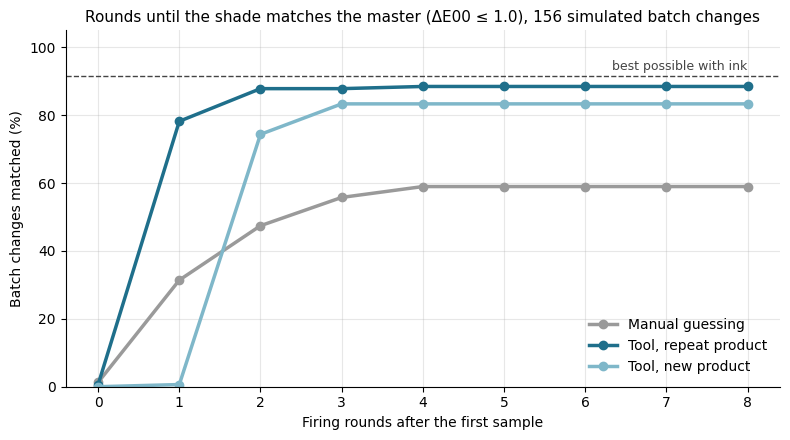

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {"Manual guessing": "#9a9a9a", "Tool, repeat product": "#1f6f8b", "Tool, new product": "#7fb7c9"}
xs = np.arange(0, 9)
for name, r in results.items():
    ok = np.array([x for x in r if x is not None])
    ax.plot(xs, [100 * np.sum(ok <= k) / n for k in xs], marker="o", lw=2.5, color=colors[name], label=name)
ax.axhline(100 * reachable.mean(), color="#444444", ls="--", lw=1)
ax.text(8, 100 * reachable.mean() + 1.5, "best possible with ink", ha="right", fontsize=9, color="#444444")
ax.set_xlabel("Firing rounds after the first sample")
ax.set_ylabel("Batch changes matched (%)")
ax.set_title(f"Rounds until the shade matches the master (ΔE00 ≤ {TOL}), {n} simulated batch changes", fontsize=11)
ax.set_xticks(xs); ax.set_ylim(0, 105); ax.grid(alpha=0.3); ax.legend(loc="lower right", frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig("rounds_to_match.png", dpi=150)
plt.show()

## 7. Failure case 1: out of reach (the glaze came out darker)
Ink only adds colour. If the glaze/body itself is darker and yellower, the light areas
can't be made lighter with ink. The tool must **say so**, not pretend.

In [8]:
def show(log):
    for step, de in log:
        print(f"  Tool: {step}" + (f" {de:.1f}" if de is not None else ""))

rng = np.random.default_rng(SEED + 1)
cov = make_product(rng)
target = (measure(cov, np.ones(6), NOMINAL, rng) + measure(cov, np.ones(6), NOMINAL, rng)) / 2
J, _ = learn_profile(cov, np.ones(6), NOMINAL, rng)
dark_glaze = dict(strength=np.ones(6), kiln=0.0, glaze=0.10)
print("First sample ΔE00 per spot:", np.round(de2000(measure(cov, np.ones(6), dark_glaze, rng), target), 1),
      " (spot 0 = light area)")
print(f"Best possible with any ink change (perfect search): ΔE00 {best_possible(cov, target, dark_glaze):.1f}")
rounds, t, log = tool_run(cov, target, dark_glaze, np.random.default_rng(11), J=J)
show(log)
print(f"  Tool total: {t} tiles, then escalates to the glaze/body team")
m_rounds, m_tiles = manual_run(cov, target, dark_glaze, np.random.default_rng(12))
print(f"  Manual: {'matched after ' + str(m_rounds) + ' rounds' if m_rounds else 'not matched after 8 rounds'}, {m_tiles} tiles used")

First sample ΔE00 per spot: [4.7 3.7 3.9 3.4]  (spot 0 = light area)


Best possible with any ink change (perfect search): ΔE00 2.0
  Tool: check tile after fix [brown -13%, beige -15%, yellow -15%, pink +13%, black -15%]: tool promised ΔE00 3.0, got 2.7
  Tool: FLAG: can't reach the master with ink changes; best possible ΔE00 2.5
  Tool total: 2 tiles, then escalates to the glaze/body team
  Manual: not matched after 8 rounds, 49 tiles used


## 8. Failure case 2: stale profile (the kiln ran much cooler)
The tool's table was learned on a normal day. Then the kiln runs much cooler than usual.
The tool's first fix does clearly less than it promised, so it **notices the table is stale**,
re-learns with 8 tiles, and then tells the truth about what ink can and can't do.

In [9]:
rng = np.random.default_rng(SEED + 4)
cov = make_product(rng)
target = (measure(cov, np.ones(6), NOMINAL, rng) + measure(cov, np.ones(6), NOMINAL, rng)) / 2
J, _ = learn_profile(cov, np.ones(6), NOMINAL, rng)
cool_kiln = dict(strength=np.ones(6), kiln=-3.0, glaze=0.0)
print(f"First sample mean ΔE00: {mean_de(measure(cov, np.ones(6), cool_kiln, rng), target):.1f}")
print(f"Best possible with any ink change (perfect search): ΔE00 {best_possible(cov, target, cool_kiln):.1f}")
rounds, t, log = tool_run(cov, target, cool_kiln, np.random.default_rng(21), J=J)
show(log)
print(f"  Tool total: {t} tiles, then escalates to the kiln team")
m_rounds, m_tiles = manual_run(cov, target, cool_kiln, np.random.default_rng(22))
print(f"  Manual: {'matched after ' + str(m_rounds) + ' rounds' if m_rounds else 'not matched after 8 rounds'}, {m_tiles} tiles used")

First sample mean ΔE00: 3.6
Best possible with any ink change (perfect search): ΔE00 2.1
  Tool: check tile after fix [blue +15%, brown +12%, beige +15%, yellow +15%, black +15%]: tool promised ΔE00 2.0, got 2.6
  Tool: FLAG: stale profile (the fix did not do what the tool predicted); re-learning
  Tool: learning round (8 tiles); ΔE00 now 2.6
  Tool: FLAG: can't reach the master with ink changes; best possible ΔE00 2.3
  Tool total: 10 tiles, then escalates to the kiln team
  Manual: not matched after 8 rounds, 49 tiles used


## 9. What this shows, and what it doesn't
Results with the fixed seeds above (156 simulated batch changes that needed a fix):

| | Matched after 1 round | after ≤ 2 rounds | Not matched | Tiles per event |
|---|---|---|---|---|
| Manual guessing (competent operator) | 31% | 47% | 41% | 26.7 |
| Tool, repeat product | **78%** | **88%** | 12% | **2.1** |
| Tool, new product (round 1 = 8-tile learning) | 1% | 74% | 17% | 9.9 |
| Best possible with any ink change | 92% | 92% | 8% (no one can fix) | – |

- **Shows:** with no historical data and no kiln model, 8 planned tiles give the tool enough
  to fix most batch changes in **one** check round. Of the batch changes that *can* be fixed,
  the tool (repeat product) fixed **85%** in one round vs **34%** for manual guessing, using
  ~2 tiles instead of ~27.
- **Shows:** the tool flagged **all 13** truly unfixable batch changes as "can't reach",
  with 5 false alarms out of 143 fixable ones (borderline cases near the tolerance).
- **Shows:** in both failure cases the tool stops after 2 or 10 tiles and names the likely
  cause (glaze/body, kiln), while manual guessing runs 8 rounds and 49 tiles without a match.
- **Learned along the way (honest):** stored profiles held up well under normal ink, glaze
  and kiln drift. The stale-profile check only fired under an extreme kiln change, which ink
  can't fix anyway. In the pilot it is a safety net, not something we expect daily.
- **Doesn't show:** that their real printer, glaze and kiln behave like this simulator.
  Only the pilot on their line can show that. That's why the pilot has a stop rule.